## Debugging Question 1
**Original code:**

In [3]:
import pandas as pd
from scipy.stats import ttest_ind

data = pd.DataFrame({'Group': ['A', 'A', 'B', 'B'], 'Score': [70, 80, 85, 90]})

group_A = data[data['Group'] == 'A']['Score']
group_B = data[data['Group'] == 'B']['Score']

t_stat, p_value = ttest_ind(group_A, group_B, axis=1)
print(f"T-Statistic: {t_stat}, P-Value: {p_value}")


AxisError: `axis` is out of bounds for array of dimension 1

**Corrected code:**

In [1]:
import pandas as pd
from scipy.stats import ttest_ind
data = pd.DataFrame({'Group':['A','A','B','B'],'Score':[70,80,85,90]})
a = data.loc[data.Group=='A','Score']
b = data.loc[data.Group=='B','Score']
t_stat,p_value = ttest_ind(a,b)
print('T-Statistic:',t_stat,'P-Value:',p_value)

T-Statistic: -2.23606797749979 P-Value: 0.1548457452714834


## Debugging Question 2
**Original code:**

In [4]:
import pandas as pd

df = pd.DataFrame({'A': [1, 2, 3, 4], 'B': [4, 3, 2, 1]})
correlation = df.corr(method='spearman')
print("Correlation Coefficient:", correlation[0][1])

KeyError: 0

**Corrected code:**

In [2]:
import pandas as pd
df = pd.DataFrame({'A':[1,2,3,4], 'B':[4,3,2,1]})
correlation = df.corr(method='spearman')
print('Correlation Coefficient:',correlation.loc['A','B'])

Correlation Coefficient: -1.0


## Debugging Question 3
**Original code:**

In [5]:
import pandas as pd

data = pd.DataFrame({'Name': ['Alice', 'Bob', None, 'David'],
                      'Age': [25, 30, 22, None]})

data = data.dropna('rows')
print(data)


TypeError: DataFrame.dropna() takes 1 positional argument but 2 were given

**Corrected code:**

In [6]:
import pandas as pd
data = pd.DataFrame({'Name':['Alice','Bob',None,'David'],'Age':[25,30,22,None]})
cleaned = data.dropna(axis=0)
print(cleaned)

    Name   Age
0  Alice  25.0
1    Bob  30.0


## Debugging Question 4
**Original code:**

In [7]:
import pandas as pd
from scipy.stats import f_oneway

data = pd.DataFrame({
    'Course': ['Math', 'Math', 'Science', 'Science', 'English', 'English', 'Math', 'Science', 'English'],
    'Marks': [65, 70, 85, 80, 60, 75, 72, 90, 68]
})

f_stat, p_value = f_oneway(data['Marks'])
print("F-Statistic:", f_stat)
print("P-Value:", p_value)


TypeError: At least two samples are required; got 1.

**Corrected code:**

In [8]:
import pandas as pd
from scipy.stats import f_oneway
data = pd.DataFrame({'Course':['Math','Math','Science','Science','English','English','Math','Science','English'],'Marks':[65,70,85,80,60,75,72,90,68]})
groups = [g['Marks'].to_numpy() for _,g in data.groupby('Course')]
f_stat,p_value = f_oneway(*groups)
print('F-Statistic:',f_stat)
print('P-Value:',p_value)

F-Statistic: 8.876325088339225
P-Value: 0.016118236853147873


## Debugging Question 5
**Original code:**

In [9]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

data = np.random.normal(50, 10, 1000)

plt.hist()
plt.title("PDF Plot")
plt.show()


TypeError: hist() missing 1 required positional argument: 'x'

**Corrected code:**

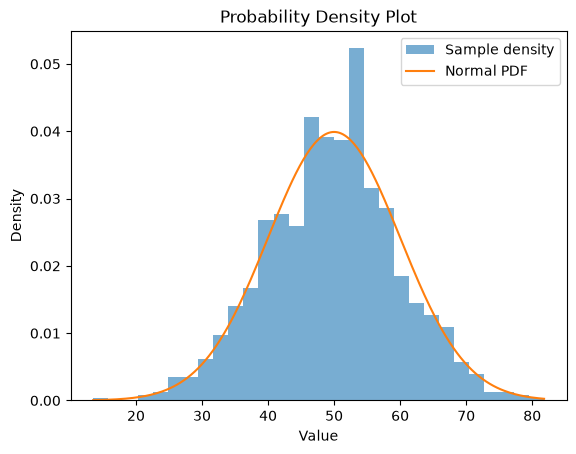

In [10]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import norm
rng = np.random.default_rng(42)
data = rng.normal(50,10,1000)
plt.hist(data,bins=30,density=True,alpha=0.6,label='Sample density')
x = np.linspace(data.min(),data.max(),250)
plt.plot(x,norm.pdf(x,loc=50,scale=10),label='Normal PDF')
plt.title('Probability Density Plot')
plt.xlabel('Value');plt.ylabel('Density');plt.legend();plt.show()